In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
#load dataset
df=pd.read_csv('/content/Social_Network_Ads.csv')
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [ ]:
df.shape

(400, 3)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [ ]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [ ]:
#idetify null values
df.isnull().sum()

,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
print("No.of records:",df.duplicated().sum())

No.of records: 33


In [ ]:
#remove duplicate records
df.drop_duplicates(inplace=True)
df.shape

(367, 3)

<Axes: ylabel='Age'>

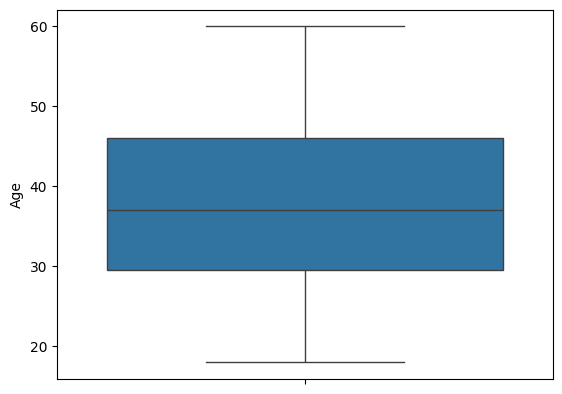

In [ ]:
#identify outliers
sns.boxplot(df['Age'])

<Axes: ylabel='EstimatedSalary'>

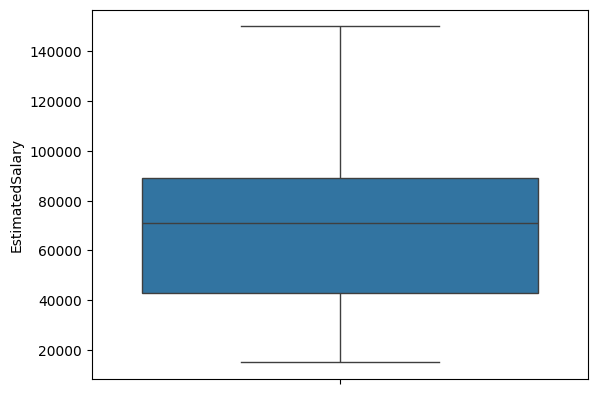

In [ ]:
#identify outliers
sns.boxplot(df['EstimatedSalary'])

<Axes: ylabel='Purchased'>

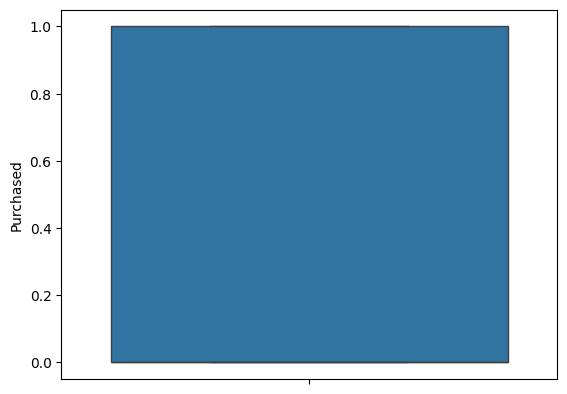

In [ ]:
#identify outliers
sns.boxplot(df['Purchased'])

In [ ]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [ ]:
#split the data into training and testing
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=15)

In [ ]:
#standardization
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [ ]:
#model building
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [ ]:
#predictions on test data
y_pred=knn.predict(x_test)

In [ ]:
#evaluation metrics
accuracy_score(y_test,y_pred)
classification_report(y_test,y_pred)
confusion_matrix(y_test,y_pred)

array([[46,  2],
       [ 2, 24]])

<Axes: >

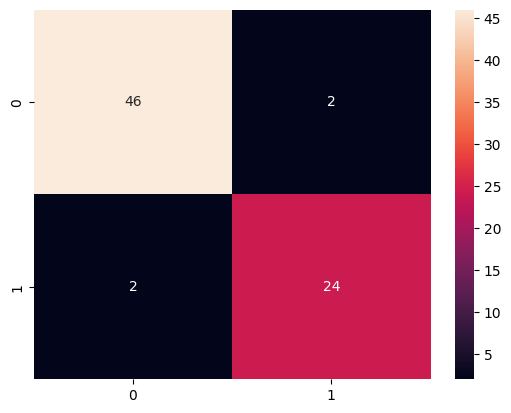

In [ ]:
#confusion matrix
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True)

In [ ]:
from sklearn.metrics import accuracy_score, roc_auc_score
y_pred = knn.predict(x_test)
y_proba = knn.predict_proba(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
roc_auc = roc_auc_score(y_test, y_proba[:, 1])
print("ROC-AUC Score:", roc_auc)

Accuracy: 0.9459459459459459
ROC-AUC Score: 0.9330929487179488


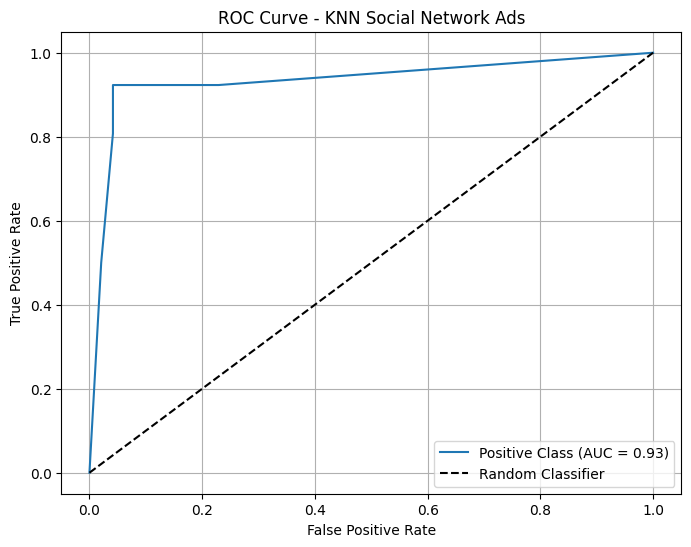

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities
y_proba = knn.predict_proba(x_test)

# For binary classification, y_test is already in the correct format (0 or 1).
# We only need the probabilities of the positive class (class 1) for ROC curve.
# y_proba[:, 1] gives the probabilities of class 1.

plt.figure(figsize=(8, 6))

# Calculate ROC curve and AUC for the positive class (class 1)
fpr, tpr, _ = roc_curve(y_test, y_proba[:, 1])
auc_score = roc_auc_score(y_test, y_proba[:, 1])

plt.plot(fpr, tpr, label=f'Positive Class (AUC = {auc_score:.2f})')

# Random classifier
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN Social Network Ads') # Updated title
plt.legend()
plt.grid()
plt.show()